Dataset Head:
    No  Transaction_Date  House_Age  Distance_to_MRT  Number_of_Stores  \
0   1       2012.916667       32.0         84.87882                10   
1   2       2012.916667       19.5        306.59470                 9   
2   3       2013.583333       13.3        561.98450                 5   
3   4       2013.500000       13.3        561.98450                 5   
4   5       2012.833333        5.0        390.56840                 5   

   Latitude  Longitude  House_Price  
0  24.98298  121.54024         37.9  
1  24.98034  121.53951         42.2  
2  24.98746  121.54391         47.3  
3  24.98746  121.54391         54.8  
4  24.97937  121.54245         43.1  

Dataset Summary:
                No  Transaction_Date   House_Age  Distance_to_MRT  \
count  414.000000        414.000000  414.000000       414.000000   
mean   207.500000       2013.148953   17.712560      1083.885689   
std    119.655756          0.281995   11.392485      1262.109595   
min      1.000000       201

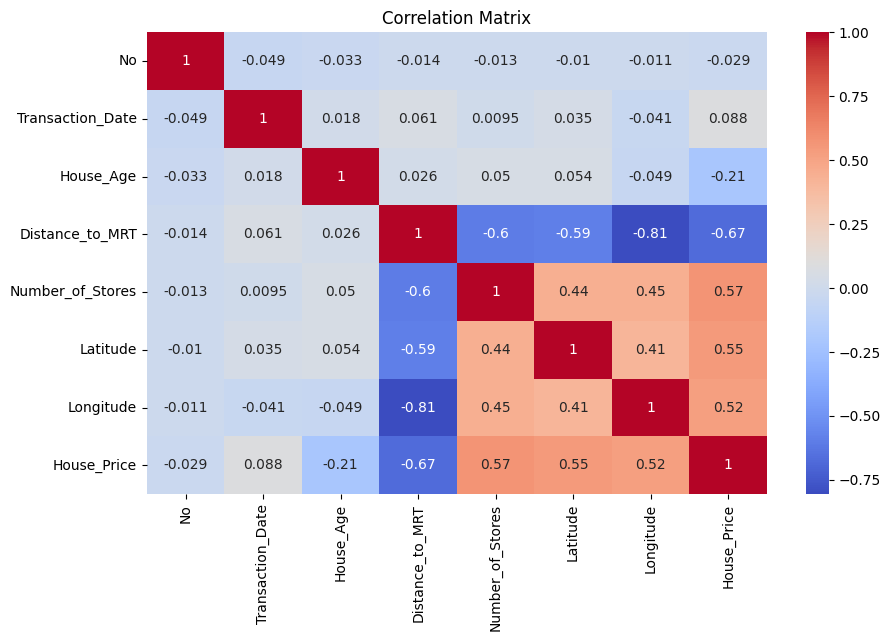

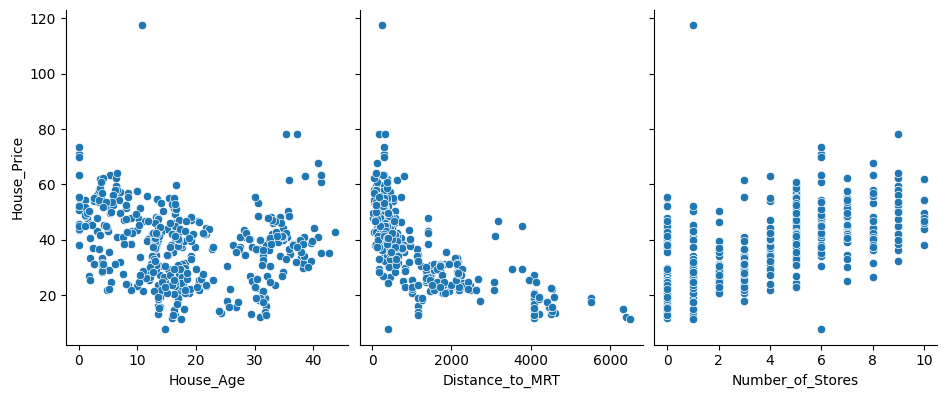

Model Coefficients: [-2.70593236e-01 -4.55249601e-03  1.10512079e+00  2.36092831e+02
 -2.39036942e+01]
Model Intercept: -2946.6588590244446
Mean Squared Error: 54.58094520086248
R-squared Score: 0.6746481382828156


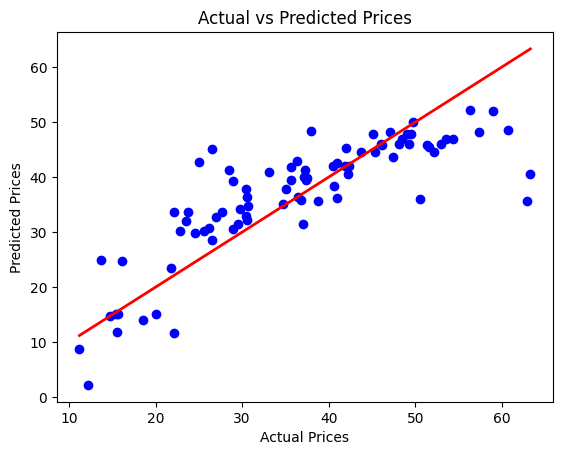

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Load the dataset
file_path = '/content/Real estate valuation data set.xlsx'  # Update if required
df = pd.read_excel(file_path)

# Step 2: Rename columns for clarity
df.columns = [
    'No', 'Transaction_Date', 'House_Age', 'Distance_to_MRT',
    'Number_of_Stores', 'Latitude', 'Longitude', 'House_Price'
]

# Step 3: Exploratory Data Analysis (EDA)
print("Dataset Head:\n", df.head())
print("\nDataset Summary:\n", df.describe())

# Visualize correlations
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Scatter plot for key variables
sns.pairplot(df, x_vars=['House_Age', 'Distance_to_MRT', 'Number_of_Stores'], y_vars='House_Price', height=4, aspect=0.8)
plt.show()

# Step 4: Prepare data for the model
X = df[['House_Age', 'Distance_to_MRT', 'Number_of_Stores', 'Latitude', 'Longitude']]
y = df['House_Price']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 5: Build the Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 6: Model Evaluation
y_pred = model.predict(X_test)

# Print coefficients and metrics
print("Model Coefficients:", model.coef_)
print("Model Intercept:", model.intercept_)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R-squared Score:", r2_score(y_test, y_pred))

# Step 7: Visualization of Predictions
plt.scatter(y_test, y_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linewidth=2)
plt.title('Actual vs Predicted Prices')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.show()
